# Notebook 02 — Exploratory Data Analysis and Data Quality

**Project:** Next-Day Wildfire Spread Prediction via Tabular ML and Spatial Deep Learning  
**Team:** TensorTitans, Section C  
**Contributor:** Tejas

## Objective

The goal of this notebook is to understand the wildfire dataset before training machine learning models. We will explore wildfire patterns, environmental conditions, and relationships between input features using simple visualizations.

### What We Will Explore
1. **Wildfire Patch Visualization:** Understand how fire spreads across a spatial grid.
2. **Environmental Feature Distributions:** Examine temperature, humidity, wind speed, and other environmental variables.
3. **Feature Correlation:** Identify relationships between environmental features.
4. **Burned vs. Unburned Comparison:** Compare environmental conditions associated with burned and unburned pixels.
5. **Data Quality:** Check for missing values and inconsistencies.

### Expected Outcome

These visualizations will help us understand the dataset, identify useful features, and prepare for the next stages of wildfire spread prediction.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")

import src.data_loader as dl

os.makedirs("../results/figures", exist_ok=True)
os.makedirs("../results/metrics", exist_ok=True)

tabular_df = dl.extract_split_tabular(
    "train",
    max_patches=30,
    sample_negatives_ratio=10.0
)

print("Dataset shape:", tabular_df.shape)
print("Missing values in the 11 input features:", tabular_df[dl.FEATURE_NAMES].isna().sum().sum())
print("\nFirst five rows:")
display(tabular_df.head())

Dataset shape: (77244, 20)
Missing values in the 11 input features: 0

First five rows:


I0000 00:00:1793218126.606601  267979 tf_record_dataset_op.cc:390] TFRecordDataset `buffer_size` is unspecified, default to 262144


,patch_id,row,col,dist_to_center,elevation,th,vs,tmmn,tmmx,sph,pr,pdsi,NDVI,population,erc,PrevFireMask,FireMask,fire_neighbor_3x3_sum,fire_neighbor_5x5_sum,split
0,train_0,17,2,1.048157,110.0,178.492386,3.070760,275.707458,293.004242,0.004699,0.0,3.863418,7376.0,0.156175,20.966082,0.0,1.0,0.0,0.0,train
1,train_0,17,3,1.020302,115.0,178.062057,3.064579,275.663116,293.011108,0.004703,0.0,3.930680,7675.0,0.787947,20.775835,0.0,1.0,0.0,0.0,train
2,train_0,17,4,0.992649,113.0,177.624466,3.058788,275.618347,293.019867,0.004707,0.0,3.994039,7360.0,1.546292,20.582205,0.0,1.0,0.0,0.0,train
3,train_0,18,1,1.062959,97.0,179.427567,3.074451,275.724030,293.011719,0.004698,0.0,3.772116,7638.0,0.479190,21.172615,0.0,1.0,0.0,0.0,train
4,train_0,18,2,1.034559,96.0,178.994476,3.067611,275.683197,293.018677,0.004702,0.0,3.838249,7992.0,0.000000,20.989607,0.0,1.0,0.0,0.0,train


### 3. Wildfire Mask Visualization

**Why are we making this graph?**

Before predicting wildfire spread, we need to understand how fire is represented in our dataset. The `FireMask` identifies the target fire conditions, while `PrevFireMask` represents the previous fire conditions.

Visualizing these masks helps us understand the spatial distribution of fire and identify areas that may be relevant to predicting future wildfire spread.

**Expected insight:** The visualization reveals the spatial pattern of fire-labelled pixels across the selected patch. It also helps us inspect whether the previous and target fire masks contain meaningful spatial patterns.

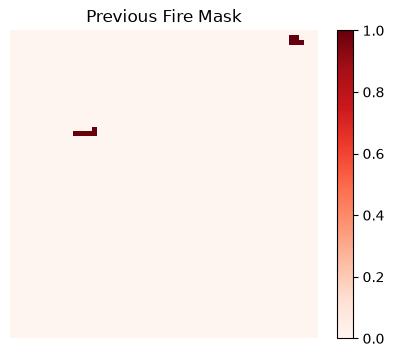

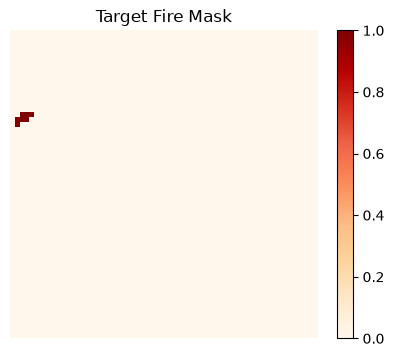

In [2]:
active_patch = None

for patch in dl.iter_records(dl.get_tfrecord_paths("train"), max_records=15):
    if np.sum(patch["FireMask"] == 1.0) > 0:
        active_patch = patch
        break

if active_patch is None:
    print("No wildfire patches found. Check your dataset path.")
else:
    plt.figure(figsize=(5, 4))
    plt.imshow(active_patch["PrevFireMask"], cmap="Reds")
    plt.title("Previous Fire Mask")
    plt.colorbar()
    plt.axis("off")
    plt.show()

    plt.figure(figsize=(5, 4))
    plt.imshow(active_patch["FireMask"], cmap="OrRd")
    plt.title("Target Fire Mask")
    plt.colorbar()
    plt.axis("off")
    plt.show()

### Key Insights

- **Sparse Fire Distribution:** Both masks contain mostly unburned pixels, with only a few fire-labelled pixels visible in the selected patch.
- **Previous Fire Mask:** Fire pixels appear in two separate locations, indicating a scattered spatial distribution of previously observed fire.
- **Target Fire Mask:** Fire pixels appear clustered near the left edge of the patch, showing a different spatial pattern from the previous mask.
- **Research Implication:** These spatial patterns highlight the importance of considering previous fire conditions when predicting next-day wildfire spread. The sparse distribution also suggests that class imbalance may be an important challenge for our prediction models.

### 4. Environmental Feature Distributions

**Why are we making these graphs?**

Wildfire spread is influenced by environmental conditions such as temperature, humidity, wind speed, elevation, and vegetation.

We visualize the distributions of eight environmental features to understand their ranges, identify skewed distributions, and detect potential outliers.

**Features analyzed:**
- `tmmx` — Maximum temperature
- `tmmn` — Minimum temperature
- `sph` — Specific humidity
- `vs` — Wind speed
- `elevation` — Terrain elevation
- `erc` — Energy Release Component
- `NDVI` — Vegetation index
- `pdsi` — Drought index

**Expected outcome:** Understand the distribution and variability of environmental conditions in the sampled wildfire dataset.

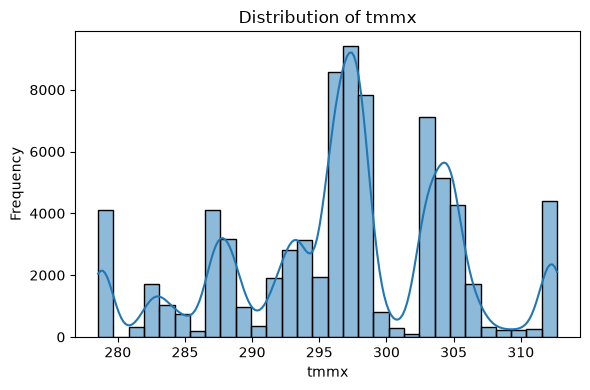

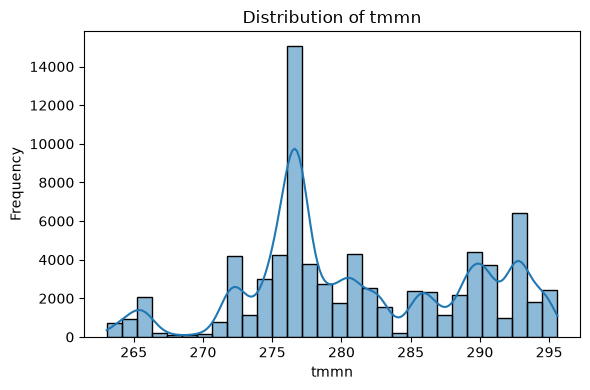

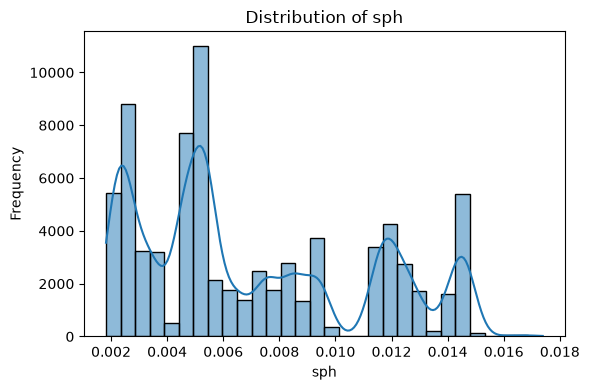

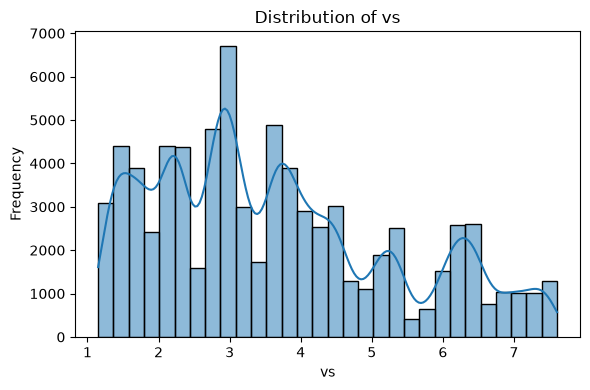

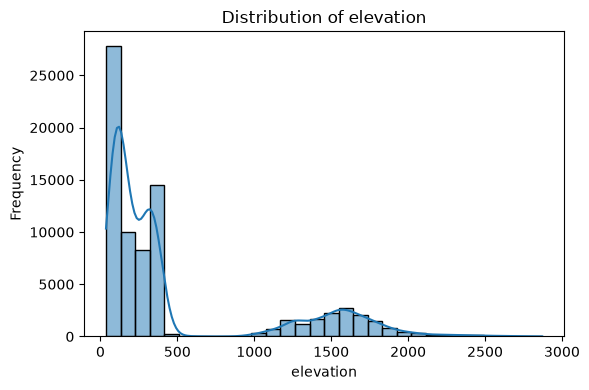

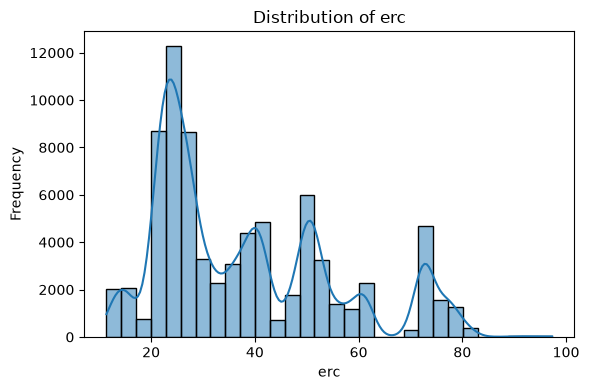

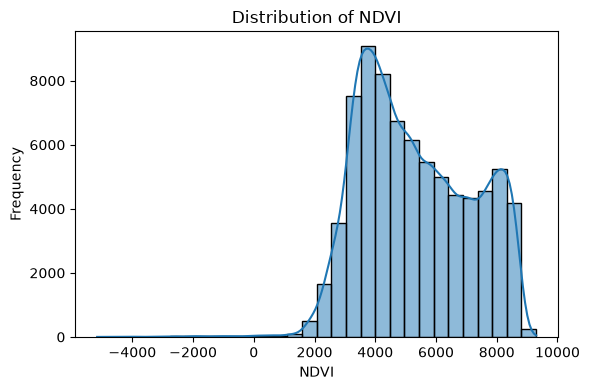

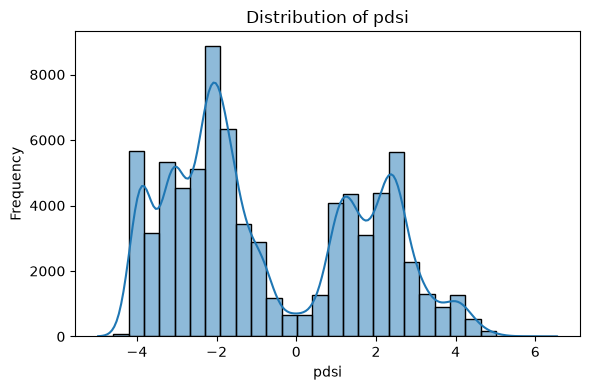

In [3]:
features = ["tmmx", "tmmn", "sph", "vs",
            "elevation", "erc", "NDVI", "pdsi"]

for feature in features:
    plt.figure(figsize=(6, 4))

    sns.histplot(
        data=tabular_df,
        x=feature,
        bins=30,
        kde=True
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.tight_layout()

    plt.savefig(
        f"../results/figures/{feature}_distribution.png",
        dpi=200
    )

    plt.show()
    plt.close()

- **Temperature:** Multiple peaks indicate varying temperature conditions across sampled regions.
- **Humidity:** Values cluster across distinct ranges, reflecting differences in atmospheric moisture.
- **Wind Speed:** About 77% of observations lie between 1 and 5 m/s, with the rest up to about 7.6 m/s.
- **Elevation:** Samples are concentrated at lower elevations, with a smaller group at higher altitudes.
- **ERC:** Multiple peaks indicate variability in fuel-related fire potential.
- **NDVI:** 145 of 77,244 rows (0.2%) are negative, down to -5,158. NDVI is stored multiplied by 10,000, so this is about -0.52; negative NDVI usually means water or bare ground, so these values are plausible rather than errors.
- **PDSI:** Multiple peaks reflect variation in drought conditions.

**Conclusion:** Environmental features show substantial variability, highlighting the need for data-quality checks and feature analysis before wildfire prediction.

### 5. Correlation Between Environmental Features

A correlation heatmap helps identify relationships between environmental variables and detect potentially redundant features. This analysis supports feature selection for wildfire spread prediction.

In [4]:
fig_dir = "../results/figures"
os.makedirs(fig_dir, exist_ok=True)

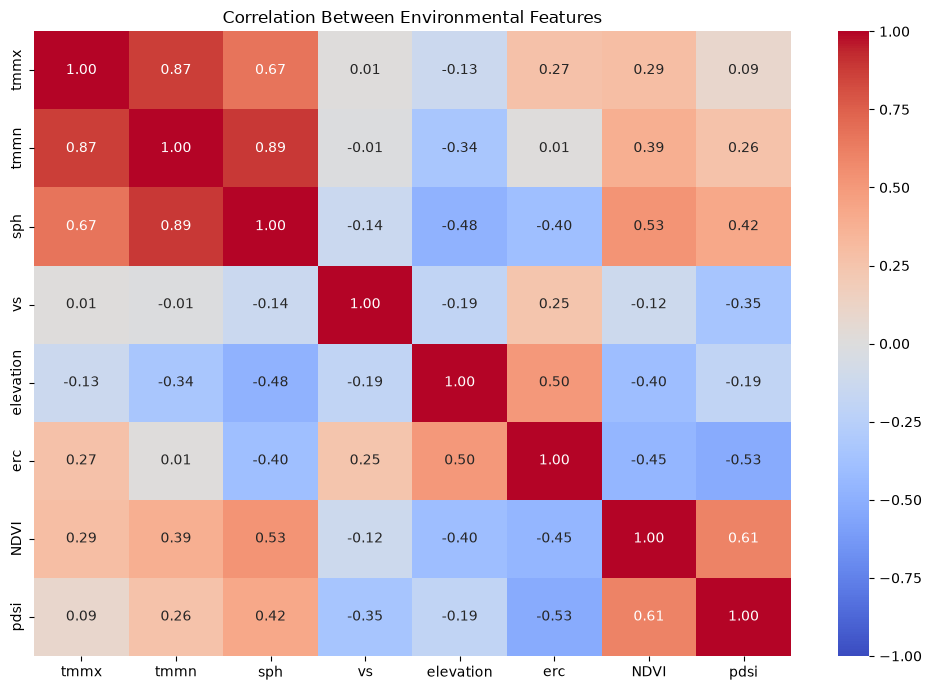

In [5]:
features = [
    "tmmx", "tmmn", "sph", "vs",
    "elevation", "erc", "NDVI", "pdsi"
]

plt.figure(figsize=(10, 7))

correlation = tabular_df[features].corr()
correlation.round(3).to_csv("../results/metrics/feature_correlation_matrix.csv")

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Environmental Features")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "correlation_heatmap.png"), dpi=250)
plt.show()
plt.close()

- **Temperature:** `tmmx` and `tmmn` show a strong positive correlation (0.87).
- **Humidity:** `sph` correlates strongly with minimum temperature (0.89).
- **Elevation:** Shows negative correlations with humidity (-0.48) and minimum temperature (-0.34), and a positive one with `erc` (0.50).
- **Fire Potential:** `erc` has a negative correlation with `pdsi` (-0.53).
- **Vegetation:** `NDVI` correlates with `pdsi` (0.61) and humidity (0.53).

**Conclusion:** Environmental variables exhibit meaningful relationships, which may influence feature selection for wildfire prediction.

### 5. Burned vs. Unburned Pixels

This graph compares the number of burned and unburned pixels to understand the class distribution in our dataset.

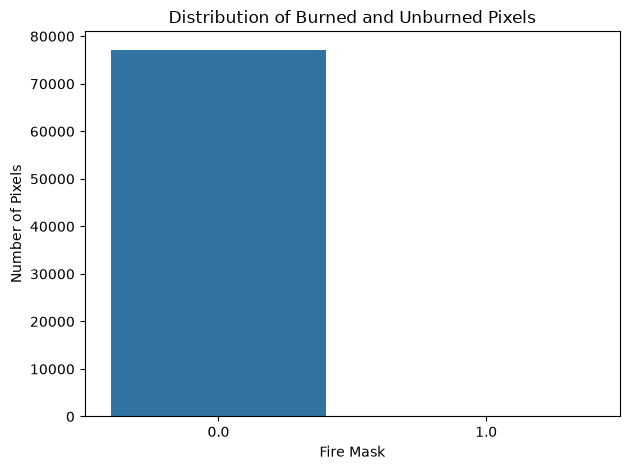

In [6]:
sns.countplot(data=tabular_df, x="FireMask")
plt.title("Distribution of Burned and Unburned Pixels")
plt.xlabel("Fire Mask")
plt.ylabel("Number of Pixels")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "fire_mask_distribution.png"), dpi=250)
plt.show()
plt.close()

**Insight:** The dataset is highly imbalanced: 77,182 unburned pixels (class 0) against only 62 burned pixels (class 1), so 0.08% of rows are fire. This imbalance may bias the model toward predicting unburned pixels.

### 6. Elevation Distribution Across Fire Pixels

This graph compares elevation values for burned and unburned pixels to explore whether terrain elevation differs between the two classes.

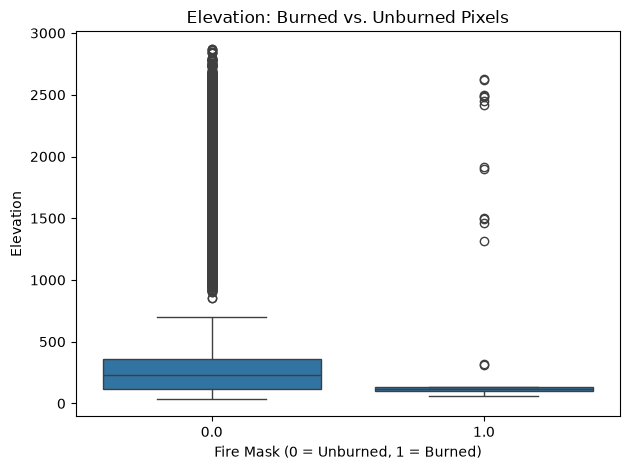

In [7]:
sns.boxplot(data=tabular_df, x="FireMask", y="elevation")
plt.title("Elevation: Burned vs. Unburned Pixels")
plt.xlabel("Fire Mask (0 = Unburned, 1 = Burned)")
plt.ylabel("Elevation")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "elevation_by_fire_mask.png"), dpi=250)
plt.show()
plt.close()

**Insight:** Burned pixels show a narrower elevation range than unburned pixels in this sample (median 113 m vs 231 m). However, there are only 62 burned pixels, so outliers and class imbalance may affect this comparison.

### 7. Maximum Temperature Distribution by Fire Class

This graph compares maximum temperature (`tmmx`) between burned and unburned pixels to explore whether temperature patterns differ across the two classes.

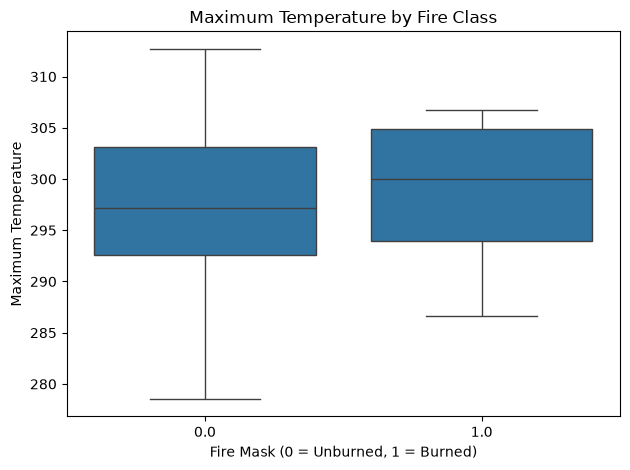

In [8]:
sns.boxplot(data=tabular_df, x="FireMask", y="tmmx")
plt.title("Maximum Temperature by Fire Class")
plt.xlabel("Fire Mask (0 = Unburned, 1 = Burned)")
plt.ylabel("Maximum Temperature")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "temperature_by_fire_class.png"), dpi=250)
plt.show()
plt.close()

### 8. Average Conditions: Fire vs No Fire

This table compares the average value of each feature for pixels that burn the next day and pixels that do not. It also shows how often a pixel is already burning today in each group.

In [9]:
compare_cols = ["tmmx", "vs", "sph", "erc", "PrevFireMask"]

class_means = tabular_df.groupby("FireMask")[compare_cols].mean().T
class_means.columns = ["No fire tomorrow", "Fire tomorrow"]
display(class_means.round(4))
class_means.to_csv("../results/metrics/burned_vs_unburned_summary.csv")

today_fire = class_means.loc["PrevFireMask", "Fire tomorrow"]
today_no_fire = class_means.loc["PrevFireMask", "No fire tomorrow"]
print("Burning today, pixels that burn tomorrow:", round(today_fire * 100, 1), "%")
print("Burning today, pixels that don't burn tomorrow:", round(today_no_fire * 100, 2), "%")
print("Ratio:", round(today_fire / today_no_fire), "times")
print("Fire pixels in this sample:", int(tabular_df["FireMask"].sum()))

,No fire tomorrow,Fire tomorrow
tmmx,296.731506,299.288788
vs,3.641100,3.673100
sph,0.007000,0.008200
erc,38.013500,35.983799
PrevFireMask,0.001300,0.161300


Burning today, pixels that burn tomorrow: 16.1 %
Burning today, pixels that don't burn tomorrow: 0.13 %
Ratio: 120 times
Fire pixels in this sample: 62


**Insight:** The weather averages are almost the same for both groups (max temperature 299.3 K vs 296.7 K, wind 3.67 vs 3.64 m/s, ERC 36.0 vs 38.0). The big difference is fire today: 16.1% of pixels that burn tomorrow are already burning, against 0.13% of the others, about 120 times more. These averages come from only 62 fire pixels.

## 9. Final Conclusion

This notebook explored wildfire spatial patterns, environmental feature distributions, feature correlations, and differences between burned and unburned pixels, using the same 30 training maps the models are trained on.

The analysis showed strong relationships between environmental variables, severe class imbalance (62 fire pixels out of 77,244), and that fire today is a much stronger clue for fire tomorrow than any weather variable.

These findings provide a foundation for data preprocessing, feature engineering, and model development. The next stage will focus on preparing reliable input features and developing models to predict next-day wildfire spread.